# 03 — Redes profundas: CNN-1D, WaveNet, SimpleRNN, LSTM, GRU e híbrida (partes B, C e D)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

| Grupo do enunciado | Modelo | Ideia central |
|---|---|---|
| B1 | CNN-1D canônica | filtros que deslizam no tempo e detectam padrões locais (um trecho de movimento) |
| B2 | WaveNet | convoluções **causais** com dilatação 1, 2, 4, 8, 16: o campo receptivo cobre os 32 instantes com poucas camadas |
| C1 | SimpleRNN (Elman) | estado oculto atualizado a cada instante; sofre com gradientes que somem |
| C2 | LSTM | memória com portas de entrada, esquecimento e saída |
| C3 | GRU | versão simplificada da LSTM (portas de atualização e de reinício) |
| D | Híbrida Conv1D → GRU | a convolução extrai padrões locais e **subamostra** o tempo (32 → 16); a GRU modela a sequência resultante |

Todas recebem a série no **formato NTC** (amostras × tempo × canais) e são treinadas com o mesmo protocolo: as 4 rodadas por sinalizante, **3 sementes**, *early stopping* na validação. As curvas de aprendizado (treino × validação) pedidas no enunciado estão na seção 5.

**Tempo:** cada treino leva de ~20 s (GPU) a alguns minutos (CPU). São 6 modelos × 4 rodadas × 3 sementes = 72 treinos. O notebook **grava cada treino assim que termina** e pula os que já existem, então pode ser interrompido (ou o Colab desconectar) e rodado de novo, que continua de onde parou.

## 1. Configuração

In [1]:
import os, sys, time, json
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

SEMENTES = [0, 1, 2]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
HIST = RES / "03_historicos"
for p in (FIG, RES, HIST):
    p.mkdir(exist_ok=True)

def salvar_fig(nome):
    plt.savefig(FIG / f"03_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes = d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
K = len(classes)

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))
print(f"séries {N} | T={T} | F={F} | classes {K}")

I0000 00:00:1795797817.412582    3356 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795797819.899536    3356 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


séries 1158 | T=32 | F=321 | classes 20


## 2. As arquiteturas

Escolhas comuns a todas, para que a comparação seja justa:

- **Entrada de comprimento livre** (`shape=(None, 321)`): o mesmo modelo aceita a série inteira ou só o seu começo. Isso é usado na classificação antecipada (notebook 05).
- **Ruído gaussiano na entrada** (σ = 0,1, só no treino) e *dropout* antes da saída: regularização, porque há ~670 vídeos de treino para ~10⁵ parâmetros.
- **Saída:** *softmax* com 20 classes; perda de entropia cruzada; otimizador Adam (taxa 10⁻³, reduzida pela metade quando a validação estaciona).
- **Causalidade:** as recorrentes leem a série da esquerda para a direita e decidem pelo último estado (só usam o passado). A WaveNet usa `padding="causal"`. A CNN-1D canônica usa `padding="same"`, que olha alguns instantes à frente **dentro da série observada**. Isso é permitido, porque a classificação é feita depois de observar a série (ou o seu começo, no notebook 05), e nunca usa instantes que ainda não foram vistos.

In [2]:
def entrada():
    x_in = keras.Input(shape=(None, F))
    return x_in, layers.GaussianNoise(0.1)(x_in)

def saida(x_in, h, nome):
    h = layers.Dropout(0.3)(h)
    return keras.Model(x_in, layers.Dense(K, activation="softmax")(h), name=nome)

def cnn1d():
    x_in, h = entrada()
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Conv1D(filtros, k, padding="same")(h)
        h = layers.BatchNormalization()(h)
        h = layers.Activation("relu")(h)
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "CNN-1D")

def wavenet(filtros=64, dilatacoes=(1, 2, 4, 8, 16)):
    # blocos residuais com ativação com porta (tanh × sigmoide), como no WaveNet original
    x_in, h = entrada()
    h = layers.Conv1D(filtros, 1)(h)
    pulos = []
    for d_ in dilatacoes:
        f = layers.Conv1D(filtros, 2, dilation_rate=d_, padding="causal", activation="tanh")(h)
        g = layers.Conv1D(filtros, 2, dilation_rate=d_, padding="causal", activation="sigmoid")(h)
        z = layers.Multiply()([f, g])
        pulos.append(layers.Conv1D(filtros, 1)(z))
        h = layers.Add()([h, layers.Conv1D(filtros, 1)(z)])
    h = layers.Activation("relu")(layers.Add()(pulos))
    h = layers.Conv1D(filtros, 1, activation="relu")(h)
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "WaveNet")

def recorrente(celula, nome, unidades=128):
    x_in, h = entrada()
    h = celula(unidades, return_sequences=True)(h)
    h = celula(unidades)(h)                       # último estado: resume a série lida até o fim
    return saida(x_in, h, nome)

def hibrida():
    x_in, h = entrada()
    h = layers.Conv1D(128, 5, padding="same", activation="relu")(h)
    h = layers.BatchNormalization()(h)
    h = layers.MaxPooling1D(2)(h)                 # subamostragem temporal: 32 -> 16 instantes
    h = layers.Conv1D(128, 3, padding="same", activation="relu")(h)
    h = layers.GRU(128)(h)
    return saida(x_in, h, "Conv1D_GRU")   # nome interno do Keras (não aceita "+")

MODELOS = {
    "CNN-1D": cnn1d,
    "WaveNet": wavenet,
    "SimpleRNN": lambda: recorrente(layers.SimpleRNN, "SimpleRNN"),
    "LSTM": lambda: recorrente(layers.LSTM, "LSTM"),
    "GRU": lambda: recorrente(layers.GRU, "GRU"),
    "Conv1D+GRU": hibrida,
}
n_param = {nome: f().count_params() for nome, f in MODELOS.items()}
display(pd.Series(n_param, name="parâmetros").map("{:,}".format).to_frame())
wn = wavenet()
print("campo receptivo da WaveNet:", 1 + sum(d_ * (2 - 1) for d_ in (1, 2, 4, 8, 16)), "instantes (a série tem 32)")

,parâmetros
CNN-1D,"197,012"
WaveNet,"146,068"
SimpleRNN,"93,076"
LSTM,"364,564"
GRU,"274,836"
Conv1D+GRU,"357,012"


campo receptivo da WaveNet: 32 instantes (a série tem 32)


## 3. Treino

Para cada rodada e semente: z-score ajustado no treino, até 200 épocas, *early stopping* pela perda na validação (paciência 25, restaura os melhores pesos) e avaliação única no teste. A semente fixa a inicialização, o ruído e a ordem dos lotes (`keras.utils.set_random_seed`).

In [3]:
ARQ_RES = RES / "03_resultados_por_rodada.csv"
feitos = pd.read_csv(ARQ_RES) if ARQ_RES.exists() else pd.DataFrame(columns=["modelo", "rodada", "semente"])
ja = set(zip(feitos.modelo, feitos.rodada, feitos.semente))
PRED = RES / "03_previsoes_semente0.csv"
prev = pd.read_csv(PRED) if PRED.exists() else pd.DataFrame({"i": np.arange(N), "y": y})

for k in range(4):
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for nome, construtor in MODELOS.items():
        for s in SEMENTES:
            if (nome, k, s) in ja:
                continue
            keras.utils.set_random_seed(s)
            m = construtor()
            m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
            cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
                  keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
            t_ini = time.time()
            h = m.fit(Z[tr], y[tr], validation_data=(Z[va], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE,
                      callbacks=cb, verbose=0)
            t_treino = time.time() - t_ini
            pred = m.predict(Z[te], verbose=0).argmax(1)
            melhor_ep = int(np.argmin(h.history["val_loss"])) + 1
            linha = dict(modelo=nome, rodada=k, semente=s, epocas=len(h.history["loss"]), melhor_epoca=melhor_ep,
                         parametros=m.count_params(), tempo_s=t_treino, **metricas(y[te], pred))
            pd.DataFrame(h.history).to_csv(HIST / f"{nome}_r{k}_s{s}.csv", index_label="epoca")
            feitos = pd.concat([feitos, pd.DataFrame([linha])], ignore_index=True)
            feitos.to_csv(ARQ_RES, index=False)
            if s == 0:
                if nome not in prev:
                    prev[nome] = -1
                prev.loc[te, nome] = pred
                prev.to_csv(PRED, index=False)
            print(f"rodada {k} | {nome:10s} | semente {s} | F1 teste {linha['f1_macro']:.3f} | acc {linha['acuracia']:.3f} "
                  f"| {melhor_ep}/{linha['epocas']} épocas | {t_treino:.0f}s", flush=True)
            keras.backend.clear_session()
res = feitos.copy()
print("treinos concluídos:", len(res))

rodada 0 | CNN-1D     | semente 0 | F1 teste 0.906 | acc 0.931 | 43/68 épocas | 38s


rodada 0 | CNN-1D     | semente 1 | F1 teste 0.911 | acc 0.931 | 73/98 épocas | 48s


rodada 0 | CNN-1D     | semente 2 | F1 teste 0.907 | acc 0.931 | 24/49 épocas | 29s


rodada 0 | WaveNet    | semente 0 | F1 teste 0.874 | acc 0.902 | 10/35 épocas | 41s


rodada 0 | WaveNet    | semente 1 | F1 teste 0.890 | acc 0.898 | 13/38 épocas | 38s


rodada 0 | WaveNet    | semente 2 | F1 teste 0.857 | acc 0.887 | 17/42 épocas | 47s


... (63 outputs left out)

rodada 3 | Conv1D+GRU | semente 0 | F1 teste 0.919 | acc 0.919 | 26/51 épocas | 26s


rodada 3 | Conv1D+GRU | semente 1 | F1 teste 0.880 | acc 0.878 | 17/42 épocas | 22s


rodada 3 | Conv1D+GRU | semente 2 | F1 teste 0.885 | acc 0.885 | 10/35 épocas | 17s


treinos concluídos: 72


## 4. Tabela comparativa (partes B, C e D)

Média ± desvio sobre 4 rodadas × 3 sementes. A última linha de cada grupo da tabela geral (notebook 06) junta esta tabela à da parte A (notebook 02).

,acuracia,acuracia_balanceada,f1_macro,parâmetros,melhor época (média),tempo de treino (s)
modelo,,,,,,
CNN-1D,92.3 ± 1.8,92.0 ± 1.8,91.6 ± 2.0,"197,012",58,44
WaveNet,88.8 ± 2.6,88.7 ± 2.5,88.1 ± 2.7,"146,068",20,45
SimpleRNN,51.4 ± 5.7,51.5 ± 5.8,50.1 ± 6.4,"93,076",22,136
LSTM,81.1 ± 3.3,80.9 ± 3.5,79.9 ± 3.7,"364,564",11,19
GRU,85.2 ± 3.6,85.1 ± 3.6,84.4 ± 3.7,"274,836",32,29
Conv1D+GRU,89.6 ± 2.7,89.6 ± 2.3,89.0 ± 2.4,"357,012",60,39


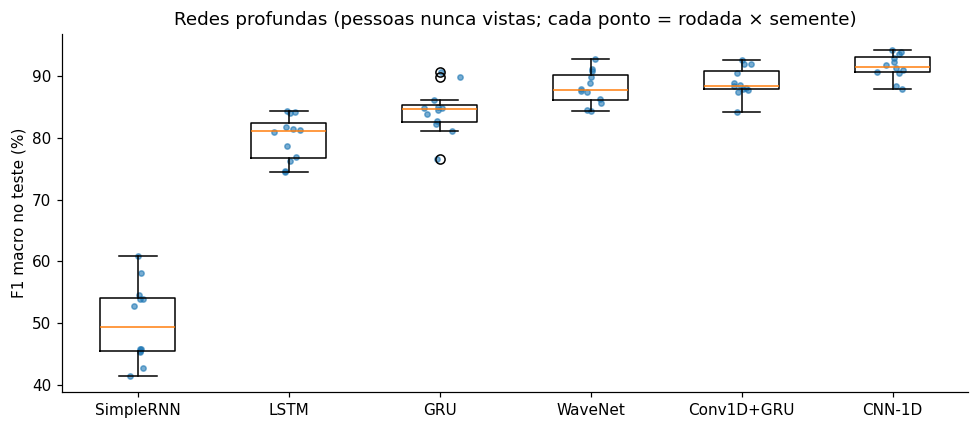

In [4]:
ordem = list(MODELOS)
tab = res.groupby("modelo")[["acuracia", "acuracia_balanceada", "f1_macro", "melhor_epoca", "tempo_s"]].agg(["mean", "std"]).reindex(ordem)
fmt = pd.DataFrame(index=tab.index)
for m in ["acuracia", "acuracia_balanceada", "f1_macro"]:
    fmt[m] = (100 * tab[(m, "mean")]).map("{:.1f}".format) + " ± " + (100 * tab[(m, "std")]).map("{:.1f}".format)
fmt["parâmetros"] = [f"{n_param[m]:,}" for m in tab.index]
fmt["melhor época (média)"] = tab[("melhor_epoca", "mean")].round(0).astype(int)
fmt["tempo de treino (s)"] = tab[("tempo_s", "mean")].round(0).astype(int)
display(fmt)
tab.to_csv(RES / "03_tabela_partesBCD.csv")

fig, ax = plt.subplots(figsize=(9, 4))
ordem_f1 = res.groupby("modelo").f1_macro.mean().sort_values().index
ax.boxplot([100 * res[res.modelo == m].f1_macro for m in ordem_f1], tick_labels=ordem_f1)
for j, m in enumerate(ordem_f1, 1):
    v = 100 * res[res.modelo == m].f1_macro
    ax.scatter(np.random.default_rng(j).normal(j, .04, len(v)), v, s=12, alpha=.6, color="tab:blue")
ax.set_ylabel("F1 macro no teste (%)"); ax.set_title("Redes profundas (pessoas nunca vistas; cada ponto = rodada × semente)")
plt.tight_layout(); salvar_fig("comparacao_redes"); plt.show()

## 5. Curvas de aprendizado (treino × validação)

Perda e acurácia por época na **rodada 0, semente 0**. A linha tracejada marca a época restaurada pelo *early stopping*. A distância entre as curvas de treino e de validação mostra o quanto cada modelo se ajusta às pessoas do treino e deixa de generalizar para pessoas novas.

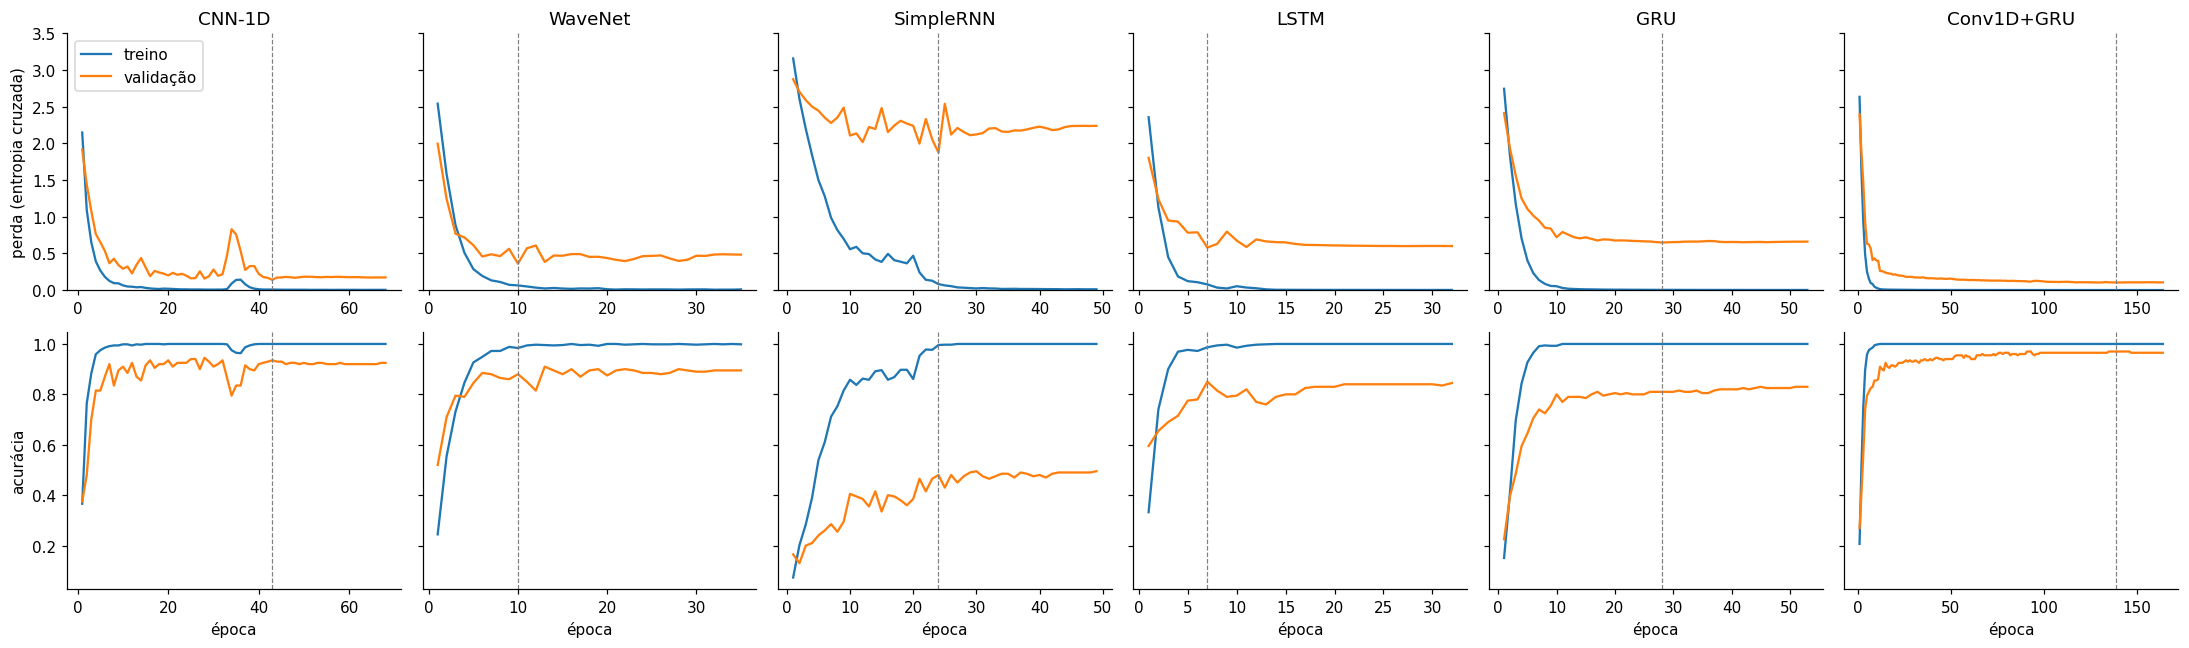

In [5]:
fig, axs = plt.subplots(2, 6, figsize=(20, 6), sharey="row")
for j, nome in enumerate(MODELOS):
    hcsv = HIST / f"{nome}_r0_s0.csv"
    if not hcsv.exists():
        continue
    h = pd.read_csv(hcsv)
    ep = np.arange(1, len(h) + 1); melhor = int(h.val_loss.idxmin()) + 1
    axs[0, j].plot(ep, h.loss, label="treino"); axs[0, j].plot(ep, h.val_loss, label="validação")
    axs[1, j].plot(ep, h.accuracy, label="treino"); axs[1, j].plot(ep, h.val_accuracy, label="validação")
    for a in axs[:, j]:
        a.axvline(melhor, ls="--", color="gray", lw=.8)
    axs[0, j].set_title(nome); axs[1, j].set_xlabel("época")
axs[0, 0].set_ylabel("perda (entropia cruzada)"); axs[1, 0].set_ylabel("acurácia"); axs[0, 0].legend()
axs[0, 0].set_ylim(0, 3.5)
plt.tight_layout(); salvar_fig("curvas_aprendizado"); plt.show()

## 6. Erros por palavra (semente 0, as 4 rodadas juntas)

In [6]:
prev = pd.read_csv(PRED)
mods = [m for m in MODELOS if m in prev]
prev = prev[(prev[mods] >= 0).all(1)]          # só vídeos já testados por todos (útil se a execução foi interrompida)
f1_pal = pd.DataFrame({m: f1_score(prev.y, prev[m], average=None, labels=range(K)) for m in mods}, index=classes)
f1_pal["média"] = f1_pal.mean(1)
display((100 * f1_pal.sort_values("média")).round(0).astype(int))
melhor = res.groupby("modelo").f1_macro.mean().idxmax()
cm = np.nan_to_num(confusion_matrix(prev.y, prev[melhor], labels=range(K), normalize="true"))
conf = pd.DataFrame([(classes[i], classes[j], cm[i, j]) for i in range(K) for j in range(K) if i != j],
                    columns=["verdadeiro", "previsto como", "fração"]).nlargest(6, "fração").round(2)
print("melhor rede:", melhor); display(conf)

,CNN-1D,WaveNet,SimpleRNN,LSTM,GRU,Conv1D+GRU,média
medo,78,69,39,59,60,76,64
filho,73,80,32,69,66,77,66
banco,86,81,19,64,79,86,69
bala,91,84,27,62,80,87,72
barulho,82,81,42,75,78,84,74
conhecer,96,88,33,70,87,94,78
aproveitar,97,79,45,77,89,84,78
cinco,89,95,46,70,91,82,79
aluno,82,89,60,71,84,93,80
amarelo,91,89,51,62,91,97,80


melhor rede: CNN-1D


,verdadeiro,previsto como,fração
298,medo,filho,0.22
248,filho,aluno,0.12
20,aluno,amarelo,0.09
215,espelho,banco,0.08
158,barulho,banco,0.08
42,amarelo,bala,0.07


## 7. Síntese para o artigo

In [7]:
r = res.groupby("modelo").f1_macro.agg(["mean", "std"]).reindex(ordem)
for m, row in r.iterrows():
    print(f"{m:11s} F1 macro = {100 * row['mean']:.1f}% ± {100 * row['std']:.1f} | {n_param[m]:,} parâmetros")

CNN-1D      F1 macro = 91.6% ± 2.0 | 197,012 parâmetros
WaveNet     F1 macro = 88.1% ± 2.7 | 146,068 parâmetros
SimpleRNN   F1 macro = 50.1% ± 6.4 | 93,076 parâmetros
LSTM        F1 macro = 79.9% ± 3.7 | 364,564 parâmetros
GRU         F1 macro = 84.4% ± 3.7 | 274,836 parâmetros
Conv1D+GRU  F1 macro = 89.0% ± 2.4 | 357,012 parâmetros


**Leitura** (execução na GPU local, RTX 3060 no WSL2; 72 treinos. A 1ª execução, no Colab, está guardada em `resultados/_v1_colab_03/` e deu a mesma ordem entre os modelos):

| Modelo | F1 macro | Acurácia | Acurácia balanceada | Parâmetros | Melhor época (média) |
|---|---|---|---|---|---|
| **CNN-1D** | **91,6 ± 2,0** | 92,3 ± 1,8 | 92,0 ± 1,8 | 197 mil | 58 |
| Conv1D+GRU | 89,0 ± 2,4 | 89,6 ± 2,7 | 89,6 ± 2,3 | 357 mil | 60 |
| WaveNet | 88,1 ± 2,7 | 88,8 ± 2,6 | 88,7 ± 2,5 | 146 mil | 20 |
| GRU | 84,4 ± 3,7 | 85,2 ± 3,6 | 85,1 ± 3,6 | 275 mil | 32 |
| LSTM | 79,9 ± 3,7 | 81,1 ± 3,3 | 80,9 ± 3,5 | 365 mil | 11 |
| SimpleRNN | 50,1 ± 6,4 | 51,4 ± 5,7 | 51,5 ± 5,8 | 93 mil | 22 |
| *Random Forest (lags), notebook 02* | *89,0 ± 3,6* | *90,2 ± 2,8* | *89,8* | — | — |

- **Convoluções > recorrências.** A CNN-1D é a melhor rede e o único modelo que supera o Random Forest (+2,6 pontos de F1, com desvio menor). Os filtros detectam padrões locais de movimento em qualquer posição da série, e o *global average pooling* torna a decisão pouco sensível a **quando** o padrão acontece. É a defasagem entre sinalizantes vista no notebook 01. A WaveNet, restrita a olhar só o passado (convolução causal), fica 3,5 pontos abaixo da CNN não causal.
- **SimpleRNN fracassa.** Ela memoriza o treino (acurácia de treino 100%), mas a perda de validação nunca cai abaixo de ~1,9. Com 32 passos e uma única matriz de recorrência, o gradiente que chega aos primeiros instantes some, e o último estado guarda mal o começo do sinal. É a mais instável entre sementes (±6 pontos).
- **As portas resolvem parte do problema.** LSTM (80%) e GRU (84%) ganham 30 a 34 pontos da SimpleRNN. A GRU, com menos parâmetros, supera a LSTM. Com ~670 exemplos, a LSTM entra em sobreajuste muito cedo (melhor época média: 11; a perda de validação para de melhorar logo nas primeiras épocas).
- **A híbrida aproveita o melhor dos dois.** Colocar a convolução (com subamostragem 32 → 16) antes da GRU leva a GRU de 84,4% para 89,0%. A convolução entrega à recorrência padrões locais já resumidos, e a sequência fica com a metade do tamanho. Nas curvas, é o modelo cuja perda de validação desce de forma mais suave.
- **Curvas de aprendizado.** Todos os modelos chegam a ~100% de acurácia no treino em poucas épocas. O que separa os modelos é a distância até a validação, feita com **pessoas novas**. O limite aqui não é a capacidade do modelo, e sim a generalização entre sinalizantes, o mesmo diagnóstico das árvores. A CNN-1D teve um pico de instabilidade perto da época 35 (a perda de validação saltou), e o *early stopping* restaurou os pesos da época 43.
- **Acurácia balanceada ≈ acurácia:** as classes são quase balanceadas (55 a 62 vídeos por palavra), então as duas métricas ficam a menos de 0,4 ponto uma da outra.
- **Palavras difíceis:** *medo* e *filho* continuam sendo as piores para todas as redes (*medo* → *filho* em 22% dos casos na CNN-1D).